| **Inicio**         | **Siguiente 2**                                    |
| ------------------  | -------------------------------------------------- |
| [🏠](../README.md)  | [⏩](./1_2_Calculo_diferencial.ipynb) |

# 1. FUNCIONES

## 1.1 ¿Qué es realmente una función?

Una función es una regla que asigna a cada entrada válida **exactamente una salida**.

$$
f:x\mapsto y
$$

Por ejemplo:

$$
f(x)=x^2-3x+2
$$

Si:

$$
x=4
$$

entonces:

$$
f(4)=4^2-3(4)+2
$$

$$
f(4)=16-12+2=6
$$

La idea importante para SciML es:

> Una función es una forma matemática de representar una relación entre variables.

Por ejemplo, la temperatura de una habitación:

$$
T(t)
$$

donde:

* \(t\) = tiempo
* \(T\) = temperatura.

La velocidad de un vehículo:

$$
v(t)
$$

La posición:

$$
x(t)
$$

La presión:

$$
P(t)
$$

Una red neuronal también puede entenderse, en esencia, como una función extremadamente complicada:

$$
f_\theta(x)
$$

donde $(\theta)$ representa los parámetros aprendidos.

# 1.2 Funciones lineales

$$
f(x)=mx+b
$$

Ejemplo:

$$
f(x)=3x-5
$$

Aquí:

* $(m=3)$ → pendiente.
* $(b=-5)$ → intersección con eje $(y)$.

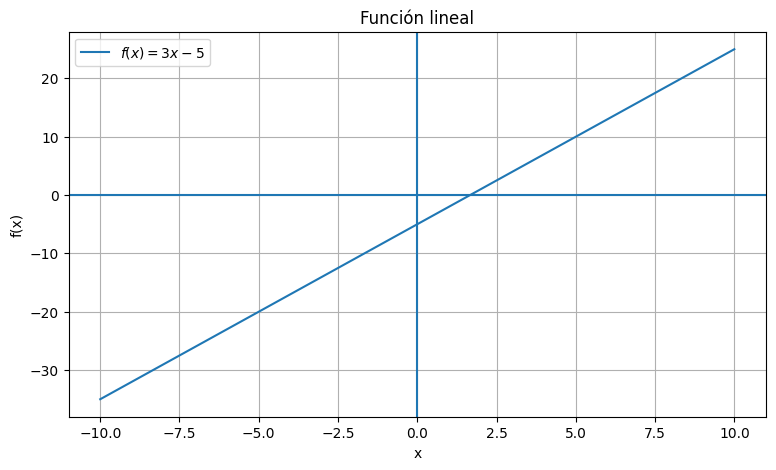

In [1]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-10, 10, 500)
y = 3*x - 5

plt.figure(figsize=(9, 5))
plt.plot(x, y, label=r"$f(x)=3x-5$")
plt.axhline(0)
plt.axvline(0)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title("Función lineal")
plt.grid(True)
plt.legend()
plt.show()

# 1.3 Funciones cuadráticas

$$
f(x)=ax^2+bx+c
$$

Ejemplo:

$$
f(x)=x^2-6x+5
$$

Podemos completar cuadrados:

$$
x^2-6x+5
$$

$$
=(x-3)^2-4
$$

Esto nos dice inmediatamente que el vértice es:

$$
(3,-4)
$$

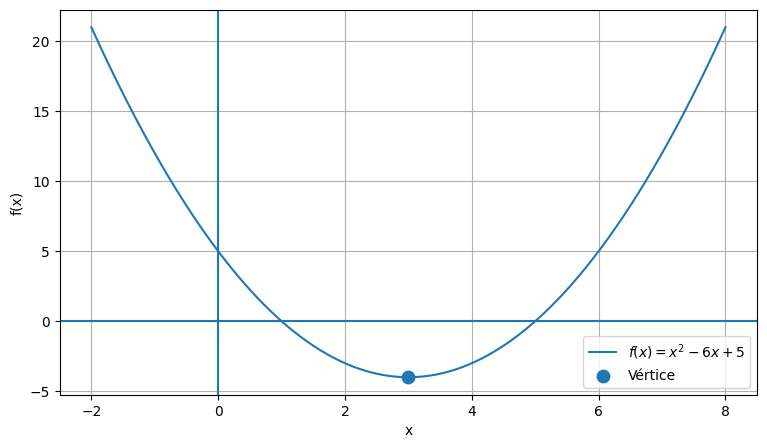

In [2]:
x = np.linspace(-2, 8, 500)
f = x**2 - 6*x + 5

plt.figure(figsize=(9, 5))
plt.plot(x, f, label=r"$f(x)=x^2-6x+5$")
plt.scatter([3], [-4], s=80, label="Vértice")

plt.axhline(0)
plt.axvline(0)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.grid(True)
plt.legend()
plt.show()

# 1.4 Funciones más complicadas

En SciML aparecerán funciones como:

$$
f(x)=e^{-x^2}\sin(5x)
$$

Esta función combina:

* exponencial
* potencia
* trigonometría
* producto.

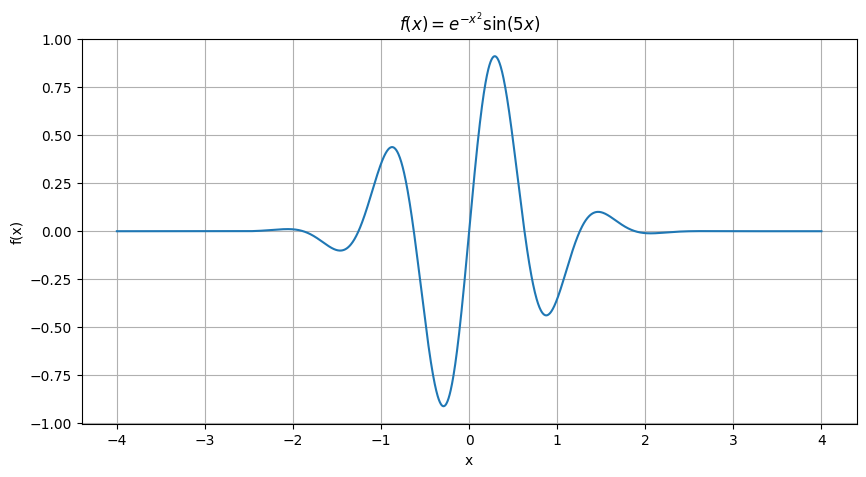

In [3]:
x = np.linspace(-4, 4, 2000)

f = np.exp(-x**2) * np.sin(5*x)

plt.figure(figsize=(10, 5))
plt.plot(x, f)

plt.xlabel("x")
plt.ylabel("f(x)")
plt.title(r"$f(x)=e^{-x^2}\sin(5x)$")
plt.grid(True)
plt.show()

Esta clase de función es muy importante porque las funciones de este tipo aparecen constantemente en física, procesamiento de señales y ecuaciones diferenciales.

# 1.5 Ejemplo de vida real: depreciación

Supongamos que una máquina cuesta:

$$
P_0=50\,000
$$

y pierde el 15 % de su valor cada año.

Entonces:

$$
V(t)=50000(0.85)^t
$$

Esto es una función exponencial.

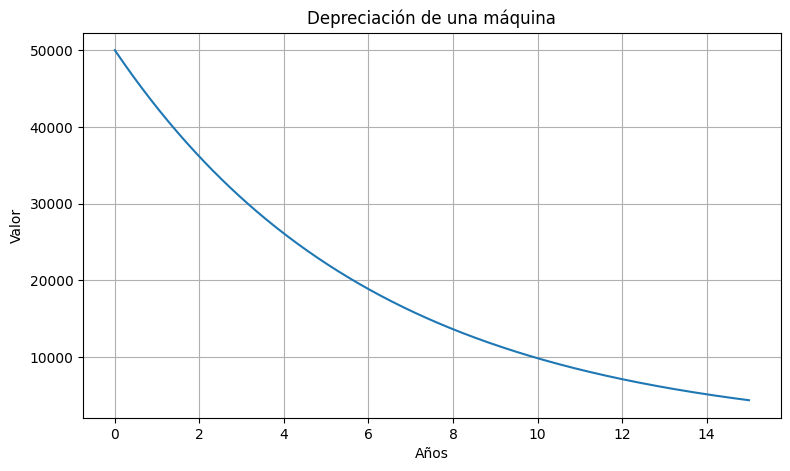

In [4]:
t = np.linspace(0, 15, 500)

V = 50000 * 0.85**t

plt.figure(figsize=(9, 5))
plt.plot(t, V)

plt.xlabel("Años")
plt.ylabel("Valor")
plt.title("Depreciación de una máquina")
plt.grid(True)
plt.show()

# 2. DOMINIO Y RANGO

Esto es **fundamental**.

## Dominio

Es el conjunto de valores que puedes introducir.

## Rango

Es el conjunto de valores que puedes obtener.

# 2.1 Ejemplo sencillo

$$
f(x)=x^2
$$

Podemos introducir cualquier número real:

$$
D=(-\infty,\infty)
$$

Pero:

$$
x^2\geq0
$$

por lo tanto:

$$
R=[0,\infty)
$$

# 2.2 Ejemplo difícil

Considera:

$$
f(x)=\frac{\sqrt{x-2}}{x-5}
$$

Tenemos dos restricciones.

### Primera

Por la raíz:

$$
x-2\geq0
$$

por tanto:

$$
x\geq2
$$

### Segunda

El denominador no puede ser cero:

$$
x-5\neq0
$$

por tanto:

$$
x\neq5
$$

Entonces:

$$
D=[2,5)\cup(5,\infty)
$$

Esto es exactamente el tipo de razonamiento que posteriormente necesitarás cuando trabajes con modelos científicos.

# 2.3 ¿Por qué importa en SciML?

Supongamos:

$$
u(x)=\sqrt{1-x^2}
$$

Esto solamente tiene sentido cuando:

$$
1-x^2\geq0
$$

$$
-1\leq x\leq1
$$

Si intentas alimentar a un modelo con valores fuera del dominio:

In [5]:
x = np.linspace(-2, 2, 500)

y = np.sqrt(1 - x**2)

/tmp/ipykernel_131186/3003521438.py:3: RuntimeWarning: invalid value encountered in sqrt
  y = np.sqrt(1 - x**2)


aparecerán valores inválidos.

Visualización:

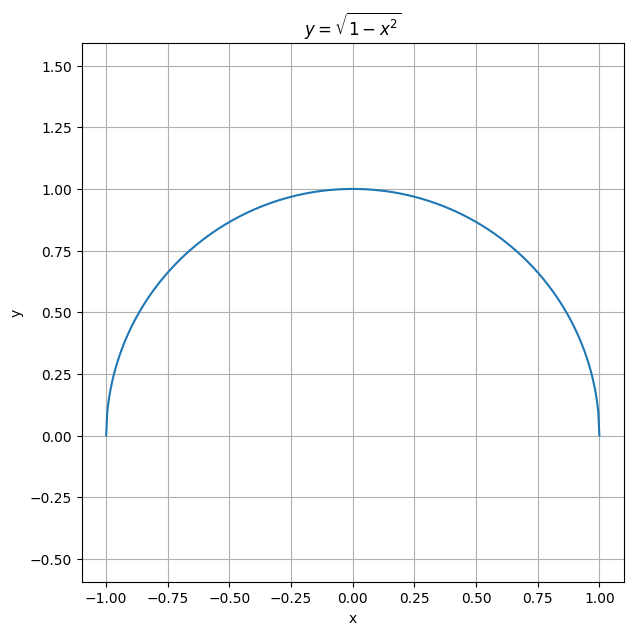

In [6]:
x = np.linspace(-1, 1, 500)
y = np.sqrt(1 - x**2)

plt.figure(figsize=(7, 7))
plt.plot(x, y)

plt.xlabel("x")
plt.ylabel("y")
plt.title(r"$y=\sqrt{1-x^2}$")
plt.axis("equal")
plt.grid(True)
plt.show()

# 3. COMPOSICIÓN DE FUNCIONES

Supongamos:

$$
f(x)=x^2+1
$$

y:

$$
g(x)=3x-2
$$

La composición:

$$
(f\circ g)(x)
$$

significa:

$$
f(g(x))
$$

Primero aplicas $(g)$, después $(f)$.

$$
g(x)=3x-2
$$

Entonces:

$$
f(g(x))=(3x-2)^2+1
$$

# 3.1 Ejemplo más complicado


Considera:

$$
f(x)=\ln(x)
$$

$$
g(x)=x^2+1
$$

Entonces:

$$
(f\circ g)(x)
$$

es:

$$
\ln(x^2+1)
$$

Pero:

$$
(g\circ f)(x)
$$

es:

$$
(\ln x)^2+1
$$

Y:

$$
\boxed{f(g(x))\neq g(f(x))}
$$

en general.

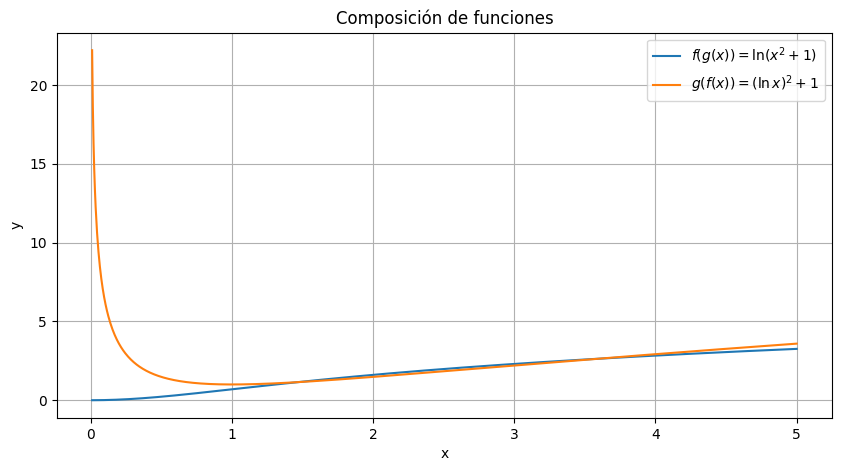

In [7]:
x = np.linspace(0.01, 5, 1000)

f_g = np.log(x**2 + 1)
g_f = np.log(x)**2 + 1

plt.figure(figsize=(10, 5))

plt.plot(x, f_g, label=r"$f(g(x))=\ln(x^2+1)$")
plt.plot(x, g_f, label=r"$g(f(x))=(\ln x)^2+1$")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Composición de funciones")
plt.grid(True)
plt.legend()
plt.show()

# 3.2 Aplicación real

Una cadena de sensores puede verse como composición:

$$
\text{temperatura}
\rightarrow
\text{voltaje}
\rightarrow
\text{señal digital}
\rightarrow
\text{temperatura estimada}
$$

Matemáticamente:

$$
T\rightarrow V(T)\rightarrow ADC(V)\rightarrow \hat T
$$

Esto es composición de funciones.

En SciML, muchas veces tendrás:

$$
x
\rightarrow
\text{transformación}
\rightarrow
\text{modelo físico}
\rightarrow
\text{predicción}
$$

# 4. FUNCIONES INVERSAS


Si:

$$
f(x)=3x+2
$$

queremos encontrar $(f^{-1})$.

Tenemos:

$$
y=3x+2
$$

Intercambiamos:

$$
x=3y+2
$$

Despejamos:

$$
y=\frac{x-2}{3}
$$

Por tanto:

$$
\boxed{f^{-1}(x)=\frac{x-2}{3}}
$$

Y debe cumplirse:

$$
f^{-1}(f(x))=x
$$

# 4.1 Ejemplo difícil

$$
f(x)=\frac{2x-3}{x+4}
$$

Queremos la inversa.

$$
y=\frac{2x-3}{x+4}
$$

Multiplicamos:

$$
y(x+4)=2x-3
$$

$$
xy+4y=2x-3
$$

Agrupamos $(x)$:

$$
xy-2x=-3-4y
$$

$$
x(y-2)=-3-4y
$$

$$
x=\frac{-3-4y}{y-2}
$$

Entonces:

$$
\boxed{
f^{-1}(x)=\frac{-3-4x}{x-2}
}
$$

# 4.2 ¿Dónde se utiliza?

Un ejemplo muy importante:

### Conversión de sensores

Supongamos que un sensor mide voltaje:

$$
V=0.02T^2+0.5T+2
$$

El problema real es:

> tengo $(V)$, ¿qué temperatura $(T)$ produjo ese voltaje?

Eso es un problema inverso.

Los problemas inversos son extremadamente importantes en:

* física;
* medicina;
* geofísica;
* ingeniería;
* imágenes;
* Scientific Machine Learning.

# 5. EXPONENCIALES

La función:

$$
f(x)=a^x
$$

con:

$$
a>0,\quad a\neq1
$$

# 5.1 Crecimiento

$$
f(x)=2^x
$$

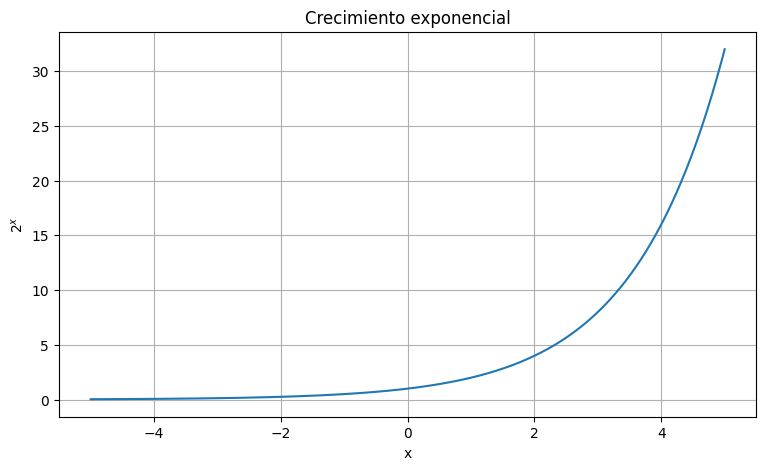

In [8]:
x = np.linspace(-5, 5, 500)

y = 2**x

plt.figure(figsize=(9, 5))
plt.plot(x, y)

plt.xlabel("x")
plt.ylabel(r"$2^x$")
plt.title("Crecimiento exponencial")
plt.grid(True)
plt.show()

# 5.2 Decaimiento

$$
f(t)=Ae^{-kt}
$$

Esto aparece muchísimo en ciencia.

Ejemplo:

$$
T(t)=20+80e^{-0.2t}
$$

Representa, por ejemplo, un objeto caliente enfriándose hacia una temperatura ambiente de $(20^\circ C)$.

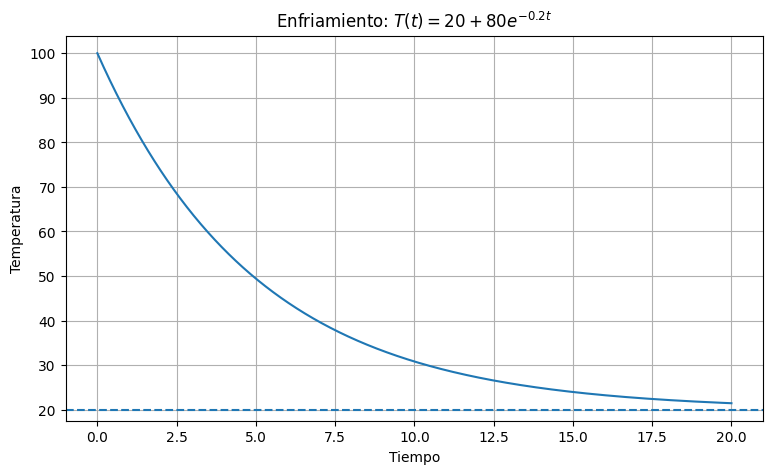

In [9]:
t = np.linspace(0, 20, 1000)

T = 20 + 80*np.exp(-0.2*t)

plt.figure(figsize=(9, 5))
plt.plot(t, T)

plt.axhline(20, linestyle="--")

plt.xlabel("Tiempo")
plt.ylabel("Temperatura")
plt.title(r"Enfriamiento: $T(t)=20+80e^{-0.2t}$")
plt.grid(True)
plt.show()

Esto es una puerta directa hacia:

$$
\frac{dT}{dt}=-k(T-T_{\text{amb}})
$$

que ya pertenece a ecuaciones diferenciales.

# 5.3 Ejemplo difícil: crecimiento logístico

Un crecimiento real normalmente no puede crecer indefinidamente.

Una población puede modelarse como:

$$
P(t)=
\frac{K}{1+Ae^{-rt}}
$$

donde:

* $(K)$ = capacidad máxima;
* $(r)$ = tasa de crecimiento;
* $(A)$ = constante.

Ejemplo:

$$
K=10000
$$

$$
A=19
$$

$$
r=0.4
$$

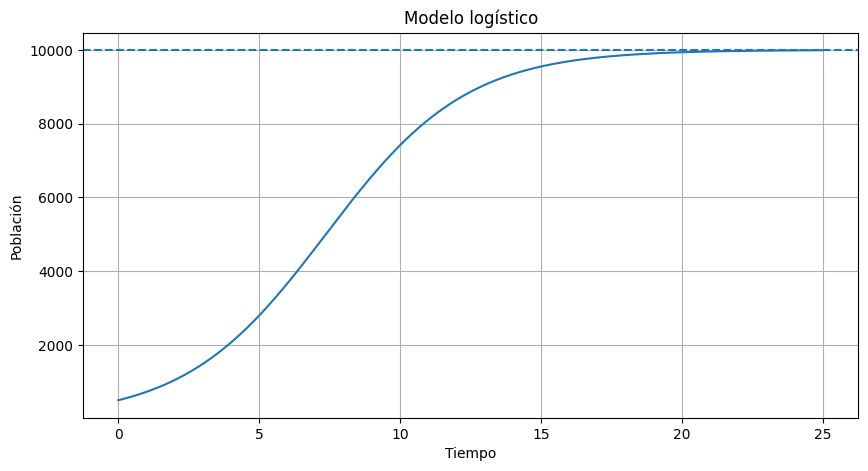

In [10]:
t = np.linspace(0, 25, 1000)

K = 10000
A = 19
r = 0.4

P = K / (1 + A*np.exp(-r*t))

plt.figure(figsize=(10, 5))
plt.plot(t, P)
plt.axhline(K, linestyle="--")

plt.xlabel("Tiempo")
plt.ylabel("Población")
plt.title("Modelo logístico")
plt.grid(True)
plt.show()

Esto es muy importante para SciML porque después estudiarás sistemas dinámicos.

# 6. LOGARITMOS

El logaritmo responde:

> ¿A qué potencia debo elevar la base para obtener este número?

$$
\log_b(x)=y
$$

significa:

$$
b^y=x
$$

Por ejemplo:

$$
\log_2(8)=3
$$

porque:

$$
2^3=8
$$

# 6.1 Logaritmo natural

El más importante en ciencia es:

$$
\ln(x)
$$

que es:

$$
\log_e(x)
$$

donde:

$$
e\approx2.71828
$$

# 6.2 Relación exponencial-logaritmo

Son funciones inversas:

$$
e^{\ln x}=x
$$

y:

$$
\ln(e^x)=x
$$

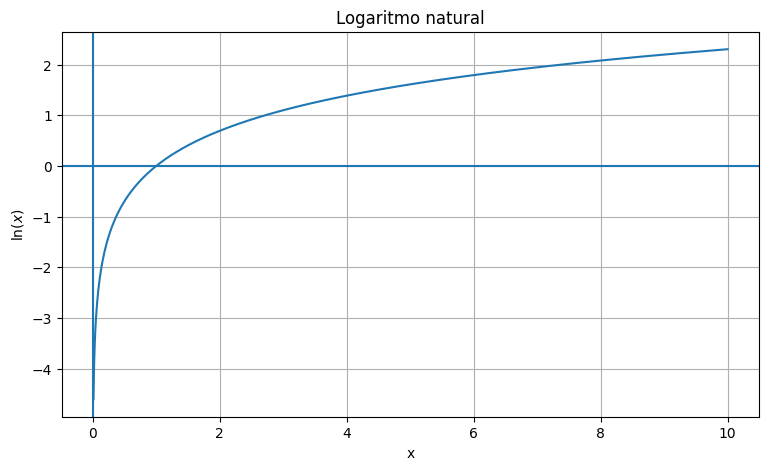

In [11]:
x = np.linspace(0.01, 10, 1000)

y = np.log(x)

plt.figure(figsize=(9, 5))
plt.plot(x, y)

plt.axhline(0)
plt.axvline(0)

plt.xlabel("x")
plt.ylabel(r"$\ln(x)$")
plt.title("Logaritmo natural")
plt.grid(True)
plt.show()

# 6.3 Aplicación científica: escala logarítmica

Muchos fenómenos abarcan órdenes de magnitud enormes.

Por ejemplo:

$$
10^0,\;10^1,\;10^2,\;10^3,\ldots
$$

Una escala logarítmica permite visualizarlos.

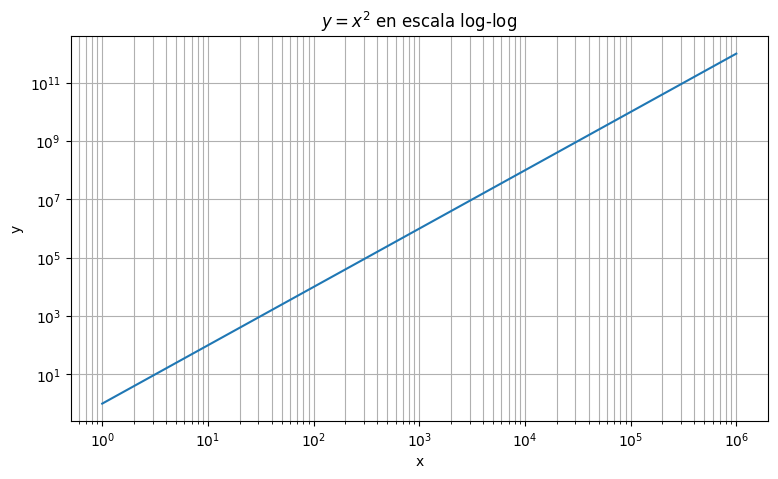

In [12]:
x = np.logspace(0, 6, 500)
y = x**2

plt.figure(figsize=(9, 5))
plt.loglog(x, y)

plt.xlabel("x")
plt.ylabel("y")
plt.title(r"$y=x^2$ en escala log-log")
plt.grid(True, which="both")
plt.show()

Esto es muy importante en:

* física;
* estadística;
* ML;
* análisis de datos;
* modelos de potencia.

# 6.4 Ejemplo difícil: resolver una ecuación

Supongamos:

$$
3e^{0.4x}=100
$$

Dividimos:

$$
e^{0.4x}=\frac{100}{3}
$$

Aplicamos \(\ln\):

$$
0.4x=\ln\left(\frac{100}{3}\right)
$$

por tanto:

$$
x=
\frac{\ln(100/3)}{0.4}
$$

In [13]:
import numpy as np

x = np.log(100/3)/0.4

print(x)

8.766394743299953


# 7. TRIGONOMETRÍA

Aquí debes aprender algo mucho más profundo que memorizar:

$$
\sin,\cos,\tan
$$

La trigonometría describe **ángulos, periodicidad y oscilaciones**.


## 7.1 Círculo unitario

El círculo unitario cumple:

$$
x^2+y^2=1
$$

y podemos parametrizarlo como:

$$
x=\cos\theta
$$

$$
y=\sin\theta
$$


Esto explica por qué:

$$
\sin^2\theta+\cos^2\theta=1
$$


# 7.2 Función seno

$$
f(x)=\sin(x)
$$

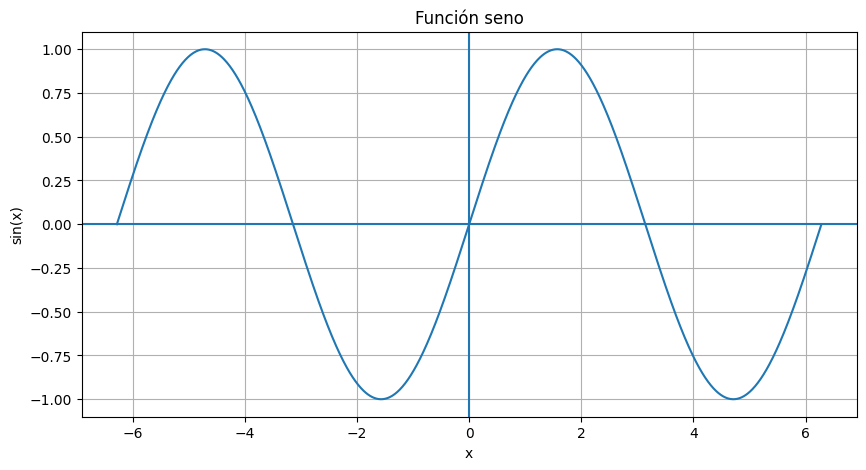

In [14]:
x = np.linspace(-2*np.pi, 2*np.pi, 1000)

y = np.sin(x)

plt.figure(figsize=(10, 5))
plt.plot(x, y)

plt.axhline(0)
plt.axvline(0)

plt.xlabel("x")
plt.ylabel("sin(x)")
plt.title("Función seno")
plt.grid(True)
plt.show()

# 7.3 Función general

Una función oscilatoria:

$$
f(t)=A\sin(\omega t+\phi)
$$

donde:

* $(A)$ = amplitud;
* $(\omega)$ = frecuencia angular;
* $(\phi)$ = fase.

Por ejemplo:

$$
f(t)=3\sin(4t+\pi/3)
$$

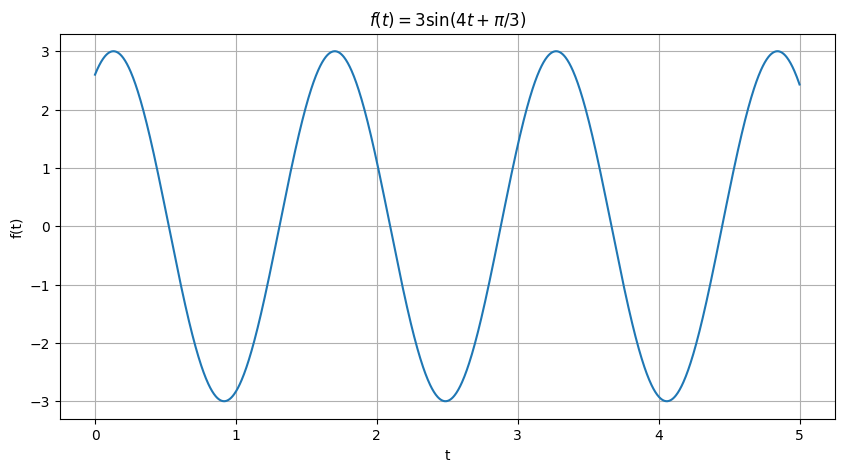

In [15]:
t = np.linspace(0, 5, 1500)

A = 3
omega = 4
phi = np.pi/3

y = A*np.sin(omega*t + phi)

plt.figure(figsize=(10, 5))
plt.plot(t, y)

plt.xlabel("t")
plt.ylabel("f(t)")
plt.title(r"$f(t)=3\sin(4t+\pi/3)$")
plt.grid(True)
plt.show()

# 7.4 Aplicación: vibración

Un sistema mecánico puede aproximarse por:

$$
x(t)=A\cos(\omega t)
$$

Por ejemplo:

* vibración de una máquina;
* onda sonora;
* corriente alterna;
* movimiento de un péndulo para pequeños ángulos;
* ondas electromagnéticas.

En SciML encontrarás constantemente datos de la forma:

$$
u(x,t)
$$

que pueden contener componentes oscilatorias.

# 7.5 Ejemplo más difícil: interferencia

Dos ondas:

$$
y_1=A\sin(\omega t)
$$

$$
y_2=A\sin(\omega t+\phi)
$$

La suma es:

$$
y=y_1+y_2
$$

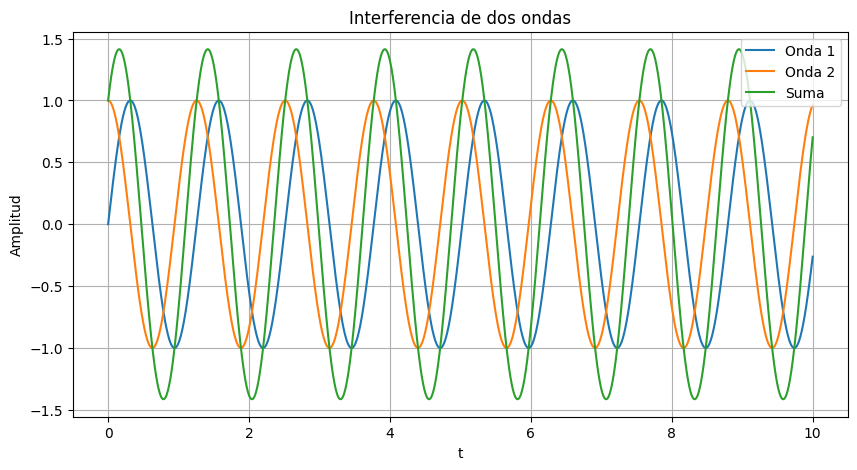

In [16]:
t = np.linspace(0, 10, 2000)

A = 1
omega = 5
phi = np.pi/2

y1 = A*np.sin(omega*t)
y2 = A*np.sin(omega*t + phi)
y = y1 + y2

plt.figure(figsize=(10, 5))
plt.plot(t, y1, label="Onda 1")
plt.plot(t, y2, label="Onda 2")
plt.plot(t, y, label="Suma")

plt.xlabel("t")
plt.ylabel("Amplitud")
plt.title("Interferencia de dos ondas")
plt.grid(True)
plt.legend()
plt.show()

Esto empieza a acercarte a señales y física computacional.

# 8. NÚMEROS COMPLEJOS

Ahora entramos en algo muy importante para ingeniería y física.

Un número complejo tiene la forma:

$$
z=a+bi
$$

donde:

$$
i^2=-1
$$

# 8.1 Ejemplo

$$
z=3+4i
$$

Parte real:

$$
Re(z)=3
$$

Parte imaginaria:

$$
Im(z)=4
$$

Su módulo:

$$
|z|=\sqrt{3^2+4^2}=5
$$

# 8.2 Representación geométrica

Un número complejo puede visualizarse como un punto:

$$
(a,b)
$$

en el plano complejo.

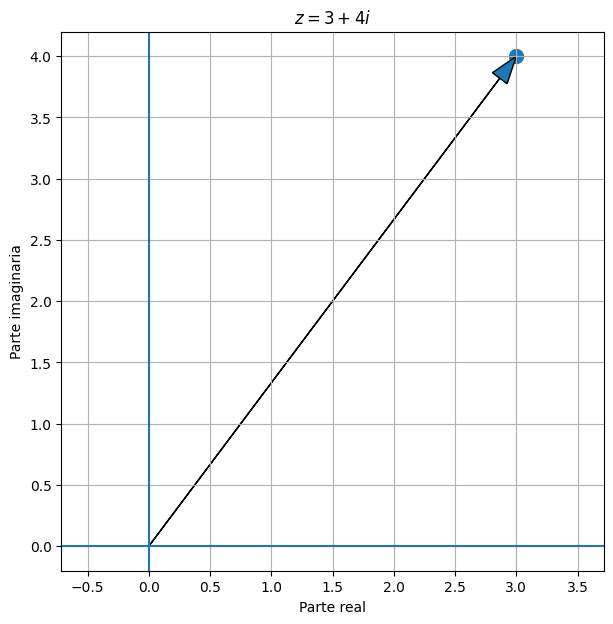

In [17]:
z = 3 + 4j

plt.figure(figsize=(7, 7))

plt.scatter([z.real], [z.imag], s=100)

plt.axhline(0)
plt.axvline(0)

plt.arrow(
    0, 0,
    z.real, z.imag,
    length_includes_head=True,
    head_width=0.15
)

plt.xlabel("Parte real")
plt.ylabel("Parte imaginaria")
plt.title(r"$z=3+4i$")
plt.grid(True)
plt.axis("equal")
plt.show()

# 8.3 Forma polar

Un complejo también puede escribirse:

$$
z=re^{i\theta}
$$

donde:

$$
r=|z|
$$

y:

$$
\theta=\arg(z)
$$

Para:

$$
z=3+4i
$$

tenemos:

$$
r=5
$$

y:

$$
\theta=\tan^{-1}(4/3)
$$

# 8.4 Fórmula de Euler

Una de las fórmulas más importantes:

$$
e^{i\theta}=\cos\theta+i\sin\theta
$$

Esto conecta:

**exponenciales + números complejos + trigonometría.**

Por ejemplo:

$$
e^{i\pi}=-1
$$

y por tanto:

$$
\boxed{e^{i\pi}+1=0}
$$

# 8.5 Graficar $(e^{it})$

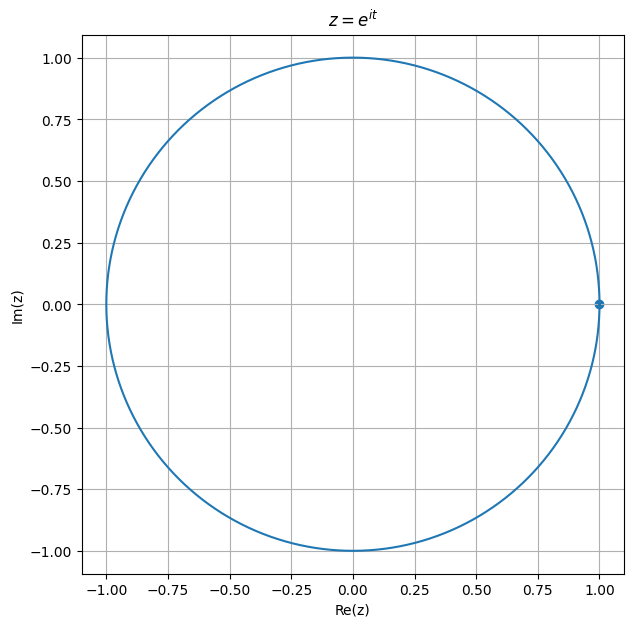

In [18]:
t = np.linspace(0, 2*np.pi, 1000)

z = np.exp(1j*t)

plt.figure(figsize=(7, 7))

plt.plot(z.real, z.imag)

plt.scatter([1], [0])

plt.xlabel("Re(z)")
plt.ylabel("Im(z)")
plt.title(r"$z=e^{it}$")
plt.grid(True)
plt.axis("equal")
plt.show()


Obtienes un círculo.

Esto es extraordinariamente importante para señales, Fourier, ondas y sistemas dinámicos.

# 8.6 Ejemplo difícil: raíces complejas

Considera:

$$
z^4=1
$$

Las soluciones son:

$$
z_k=e^{i2\pi k/4}
$$

para:

$$
k=0,1,2,3
$$

Es decir:

$$
1,\quad i,\quad -1,\quad -i
$$

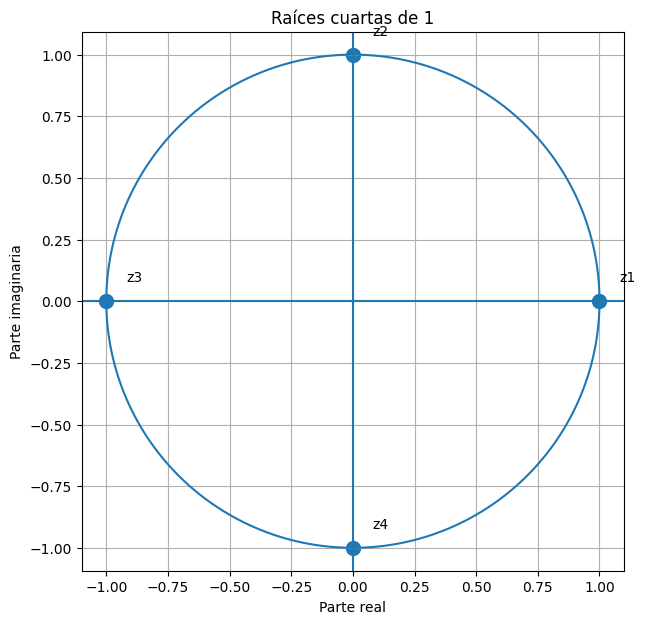

In [19]:
k = np.arange(4)

roots = np.exp(2j*np.pi*k/4)

plt.figure(figsize=(7, 7))

plt.scatter(roots.real, roots.imag, s=100)

for i, z in enumerate(roots):
    plt.text(z.real + 0.08, z.imag + 0.08, f"z{i+1}")

circle = np.exp(1j*np.linspace(0, 2*np.pi, 500))

plt.plot(circle.real, circle.imag)

plt.axhline(0)
plt.axvline(0)

plt.xlabel("Parte real")
plt.ylabel("Parte imaginaria")
plt.title("Raíces cuartas de 1")
plt.grid(True)
plt.axis("equal")
plt.show()

# 9. SUCESIONES

Una sucesión es una lista ordenada:

$$
a_1,a_2,a_3,\ldots
$$

que podemos representar como:

$$
a_n=f(n)
$$

# 9.1 Sucesión aritmética

$$
a_n=a_1+(n-1)d
$$

Ejemplo:

$$
3,7,11,15,\ldots
$$

Aquí:

$$
d=4
$$

# 9.2 Sucesión geométrica

$$
a_n=a_1r^{n-1}
$$

Ejemplo:

$$
2,6,18,54,\ldots
$$

con:

$$
r=3
$$

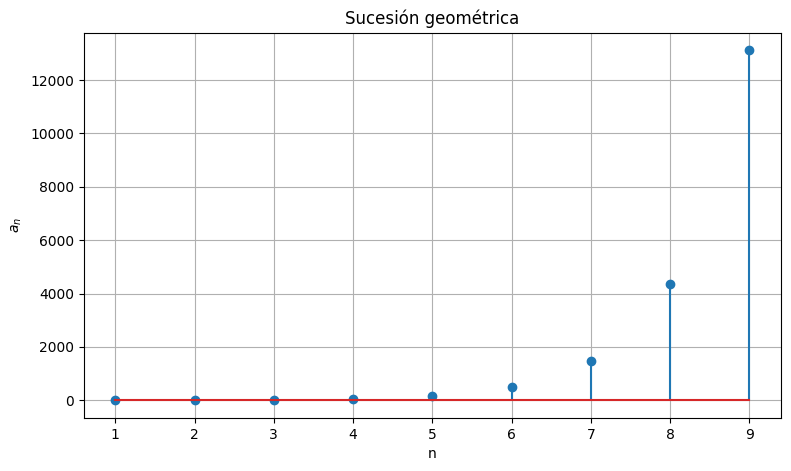

In [20]:
n = np.arange(1, 10)

a = 2 * 3**(n-1)

plt.figure(figsize=(9, 5))
plt.stem(n, a)

plt.xlabel("n")
plt.ylabel(r"$a_n$")
plt.title("Sucesión geométrica")
plt.grid(True)
plt.show()

# 9.3 Sucesión complicada


Considera:

$$
a_n=\left(1+\frac1n\right)^n
$$

Sabemos que:

$$
\lim_{n\rightarrow\infty}
\left(1+\frac1n\right)^n=e
$$

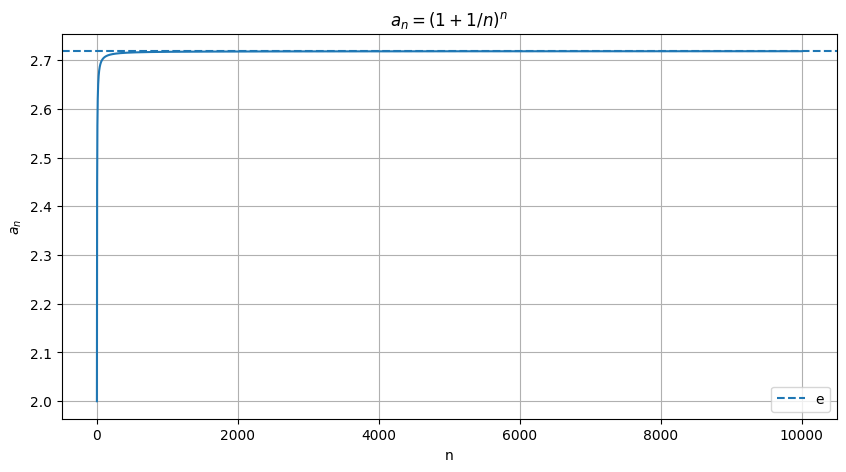

In [21]:
n = np.arange(1, 10000)

a = (1 + 1/n)**n

plt.figure(figsize=(10, 5))
plt.plot(n, a)
plt.axhline(np.e, linestyle="--", label="e")

plt.xlabel("n")
plt.ylabel(r"$a_n$")
plt.title(r"$a_n=(1+1/n)^n$")
plt.grid(True)
plt.legend()
plt.show()

Observa cómo la sucesión se aproxima a $(e)$.

# 9.4 ¿Por qué esto importa en SciML?

Los computadores trabajan con aproximaciones discretas.

En lugar de:

$$
u(t)
$$

podemos trabajar con:

$$
u_0,u_1,u_2,u_3,\ldots
$$

Por ejemplo:

$$
u_{n+1}=u_n+\Delta t\,f(u_n)
$$

Esto aparece directamente en métodos numéricos para ecuaciones diferenciales.

# 10. SERIES

Aquí aparece una transición fundamental.

Una sucesión es:

$$
a_1,a_2,a_3,\ldots
$$

Una serie es la suma:

$$
\sum_{n=1}^{\infty}a_n
$$

# 10.1 Serie geométrica

$$
\sum_{n=0}^{\infty}r^n
$$

si:

$$
|r|<1
$$

entonces:

$$
\sum_{n=0}^{\infty}r^n=
\frac{1}{1-r}
$$

Ejemplo:

$$
1+\frac12+\frac14+\frac18+\cdots
$$

$$
=2
$$

# 10.2 Verlo numéricamente

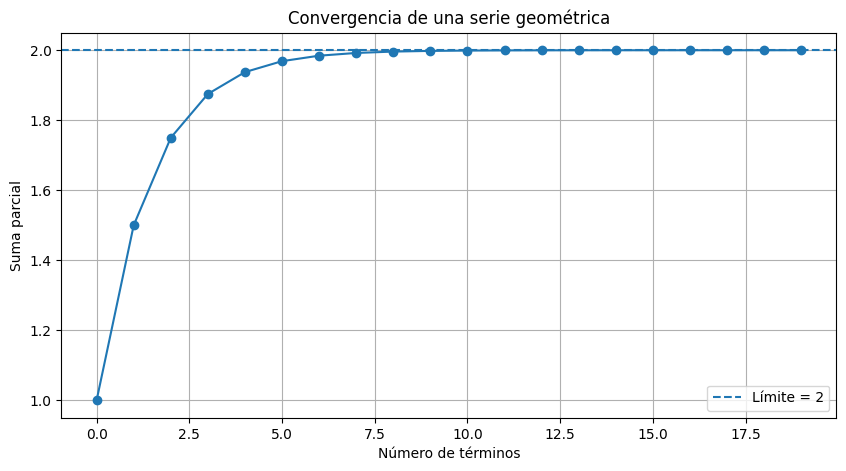

In [22]:
N = 20

n = np.arange(N)

terms = (1/2)**n
partial_sum = np.cumsum(terms)

plt.figure(figsize=(10, 5))

plt.plot(n, partial_sum, marker="o")
plt.axhline(2, linestyle="--", label="Límite = 2")

plt.xlabel("Número de términos")
plt.ylabel("Suma parcial")
plt.title("Convergencia de una serie geométrica")
plt.grid(True)
plt.legend()
plt.show()

Aquí aparece un concepto esencial:

$$
S_N=\sum_{n=0}^{N}a_n
$$

se llama **suma parcial**.


# 10.3 Serie armónica

$$
\sum_{n=1}^{\infty}\frac1n
$$

Esta serie diverge.

Es interesante porque:

$$
\frac1n\rightarrow0
$$

pero eso **no es suficiente** para garantizar convergencia.

Mira cómo crece:

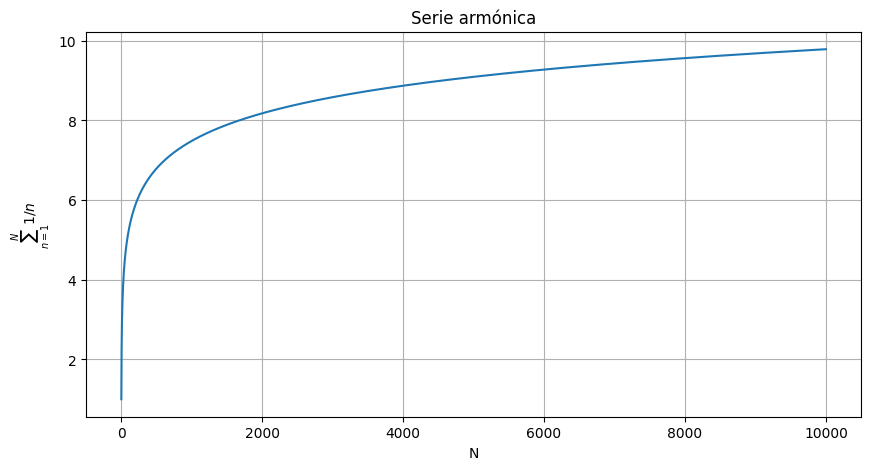

In [23]:
N = 10000

n = np.arange(1, N+1)

partial_sum = np.cumsum(1/n)

plt.figure(figsize=(10, 5))
plt.plot(n, partial_sum)

plt.xlabel("N")
plt.ylabel(r"$\sum_{n=1}^{N}1/n$")
plt.title("Serie armónica")
plt.grid(True)
plt.show()

Crece lentamente, pero sigue creciendo.

# 10.4 Serie $(p)$

Considera:

$$
\sum_{n=1}^{\infty}\frac1{n^p}
$$

La regla fundamental es:

$$
\boxed{
p>1\Rightarrow\text{converge}
}
$$

$$
\boxed{
p\leq1\Rightarrow\text{diverge}
}
$$

Por ejemplo:

$$
\sum\frac1{n^2}
$$

converge.

De hecho:

$$
\sum_{n=1}^{\infty}\frac1{n^2}
=
\frac{\pi^2}{6}
$$

# 10.5 Comparación de convergencia

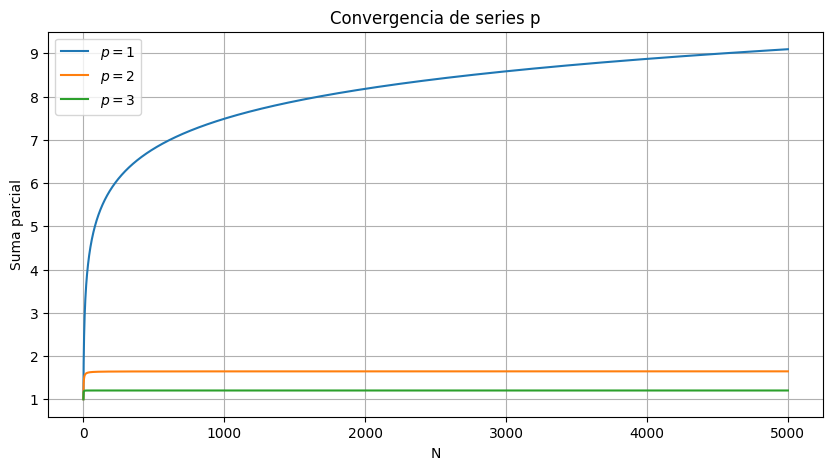

In [24]:
N = 5000
n = np.arange(1, N+1)

S1 = np.cumsum(1/n)
S2 = np.cumsum(1/n**2)
S3 = np.cumsum(1/n**3)

plt.figure(figsize=(10, 5))

plt.plot(n, S1, label=r"$p=1$")
plt.plot(n, S2, label=r"$p=2$")
plt.plot(n, S3, label=r"$p=3$")

plt.xlabel("N")
plt.ylabel("Suma parcial")
plt.title("Convergencia de series p")
plt.grid(True)
plt.legend()
plt.show()

Esto es algo que debes aprender a **interpretar**, no solamente memorizar.

# 11. SERIES DE TAYLOR

Este tema es especialmente importante para tu objetivo de SciML.

Una función complicada puede aproximarse mediante un polinomio.

Por ejemplo:

$$
e^x
$$

tiene la expansión:

$$
e^x=
1+x+\frac{x^2}{2!}
+\frac{x^3}{3!}
+\frac{x^4}{4!}
+\cdots
$$

# 11.1 Aproximación progresiva

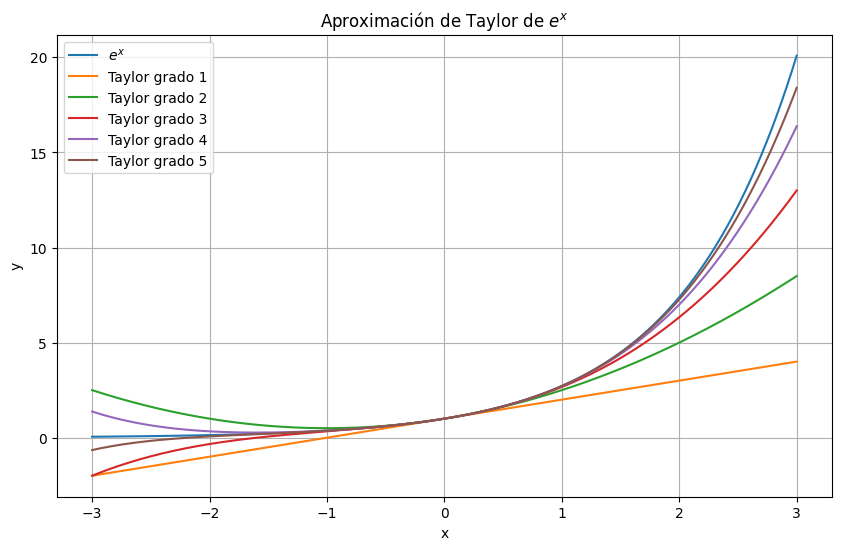

In [25]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-3, 3, 1000)

exacta = np.exp(x)

t1 = 1 + x
t2 = 1 + x + x**2/2
t3 = 1 + x + x**2/2 + x**3/6
t4 = 1 + x + x**2/2 + x**3/6 + x**4/24
t5 = t4 + x**5/120

plt.figure(figsize=(10, 6))

plt.plot(x, exacta, label=r"$e^x$")
plt.plot(x, t1, label="Taylor grado 1")
plt.plot(x, t2, label="Taylor grado 2")
plt.plot(x, t3, label="Taylor grado 3")
plt.plot(x, t4, label="Taylor grado 4")
plt.plot(x, t5, label="Taylor grado 5")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Aproximación de Taylor de $e^x$")
plt.grid(True)
plt.legend()
plt.show()

La idea:

$$
\boxed{\text{función complicada}\approx\text{polinomio}}
$$

es fundamental en matemáticas computacionales.

# 12. UN EJEMPLO QUE JUNTA CASI TODO

Ahora vamos a construir algo más cercano a Scientific Machine Learning.

Considera:

$$
u(x)=e^{-0.2x^2}\cos(5x)
$$

Aquí tenemos:

* función;
* dominio;
* rango;
* exponencial;
* trigonometría;
* composición;
* multiplicación de funciones.

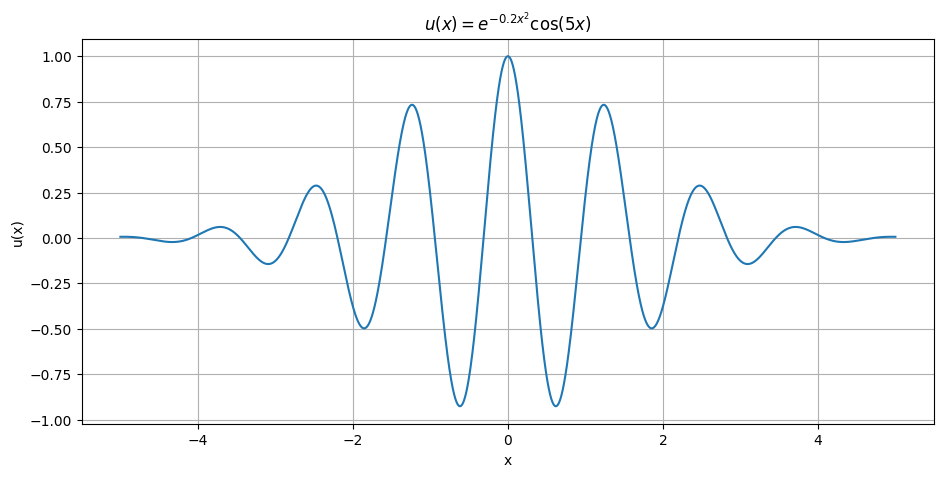

In [26]:
x = np.linspace(-5, 5, 3000)

u = np.exp(-0.2*x**2) * np.cos(5*x)

plt.figure(figsize=(11, 5))

plt.plot(x, u)

plt.xlabel("x")
plt.ylabel("u(x)")
plt.title(r"$u(x)=e^{-0.2x^2}\cos(5x)$")
plt.grid(True)
plt.show()

Esta estructura es parecida a muchas funciones que aparecen en física.

# 13. Ejemplo todavía más cercano a SciML

Supongamos que tenemos:

$$
u(x,t)=e^{-0.1x^2}\cos(3x-2t)
$$

Ahora tenemos **dos variables**:

$$
u=u(x,t)
$$

Esto ya nos lleva hacia campos físicos.

Por ejemplo:

* temperatura;
* presión;
* concentración;
* ondas;
* velocidad de un fluido.

Podemos representar el campo como una superficie.

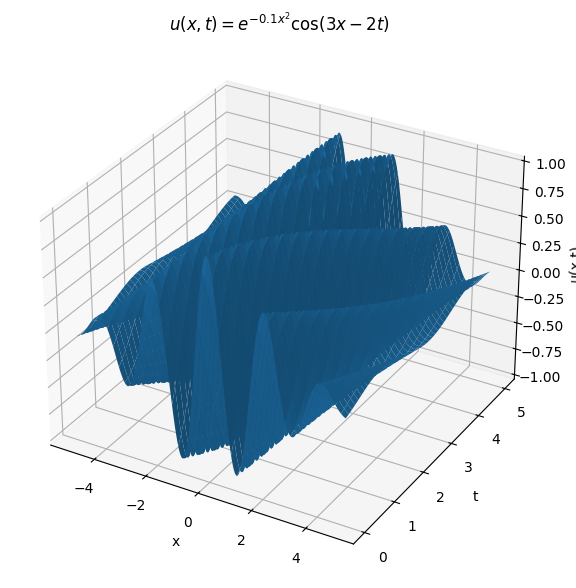

In [27]:
import numpy as np
import matplotlib.pyplot as plt

x = np.linspace(-5, 5, 300)
t = np.linspace(0, 5, 200)

X, T = np.meshgrid(x, t)

U = np.exp(-0.1*X**2) * np.cos(3*X - 2*T)

fig = plt.figure(figsize=(11, 7))

ax = fig.add_subplot(111, projection="3d")

ax.plot_surface(X, T, U)

ax.set_xlabel("x")
ax.set_ylabel("t")
ax.set_zlabel("u(x,t)")

ax.set_title(r"$u(x,t)=e^{-0.1x^2}\cos(3x-2t)$")

plt.show()

Aquí ya estás entrando conceptualmente en el mundo de:

$$
u(x,t)
$$

y posteriormente:

$$
\frac{\partial u}{\partial t}
,\qquad
\frac{\partial u}{\partial x}
,\qquad
\frac{\partial^2u}{\partial x^2}
$$

que te llevará a **PDEs (Partial Differential Equations)**.

# 14. Cómo conecta todo esto con SciML

La progresión que quiero que tengas en la cabeza es:

```text
PRECÁLCULO
│
├── Funciones
│   ├── dominio/rango
│   ├── composición
│   └── inversas
│
├── Exponenciales
│   └── crecimiento/decaimiento
│
├── Logaritmos
│   └── escalas y ecuaciones
│
├── Trigonometría
│   └── oscilaciones/ondas
│
├── Complejos
│   └── ondas/Fourier/sistemas
│
├── Sucesiones
│   └── discretización
│
└── Series
    ├── convergencia
    └── aproximaciones
             │
             ▼
        CÁLCULO
             │
      ┌──────┴──────┐
      ▼             ▼
   Derivadas     Integrales
      │             │
      └──────┬──────┘
             ▼
      ECUACIONES
      DIFERENCIALES
             │
      ┌──────┴───────┐
      ▼              ▼
      ODE            PDE
      │               │
      └───────┬───────┘
              ▼
       MÉTODOS NUMÉRICOS
              │
       ┌──────┴───────┐
       ▼              ▼
   Simulación      Optimización
       │              │
       └──────┬───────┘
              ▼
       MACHINE LEARNING
              │
              ▼
     SCIENTIFIC MACHINE
          LEARNING
```

# 15. Qué debes dominar de cada tema


No necesitas solamente saber "qué es". Para SciML yo pondría estos objetivos.

| Tema          | Debes poder hacer                                 |
| ------------- | ------------------------------------------------- |
| Funciones     | Evaluar, transformar y analizar funciones         |
| Dominio       | Encontrar restricciones algebraicamente           |
| Rango         | Determinar qué valores puede producir una función |
| Composición   | Calcular $f(g(x))$ y $g(f(x))$                |
| Inversas      | Encontrarlas y comprobarlas                       |
| Exponenciales | Resolver ecuaciones y analizar crecimiento        |
| Logaritmos    | Resolver ecuaciones exponenciales                 |
| Trigonometría | Trabajar con identidades y funciones periódicas   |
| Complejos     | Forma cartesiana/polar y operaciones              |
| Sucesiones    | Analizar comportamiento cuando $(n\to\infty)$     |
| Series        | Determinar convergencia/divergencia               |
| Taylor        | Aproximar funciones                               |
| Python        | Verificar y visualizar todo lo anterior           |



| **Inicio**         | **Siguiente 2**                                    |
| ------------------  | -------------------------------------------------- |
| [🏠](../README.md)  | [⏩](./1_2_Calculo_diferencial.ipynb) |